# Baseline Model
Follow-up to `02_2_feature_selection.ipynb`, which chose the model features and saved `data/preprocessed/model_ready.csv` with a random, stratified 80/20 train/test split.

This notebook compares 5 classification models with **stratified 5-fold cross-validation** on the training rows:
1. Load the model-ready data
2. Set up the folds and the class weights
3. Train and score every model on every fold
4. Compare the models and look closer at the best one (mistakes, the Disrupted threshold, feature importance)

**The test set is not used in this notebook.** Every number here comes from cross-validation on the training rows. The test set is scored once, at the very end of the project, after tuning. Each time the test set is used to make a choice, its score becomes a less fair estimate of how the model will do on new data.

## 1. Load Model-Ready Data
Load `model_ready.csv` and separate the training rows from the test rows using the `split` column from 02_2.

The model features are every column except the identifiers (`date`, `route_id`, `split`) and the target (`route_status`).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

model_ready_df = pd.read_csv("../data/preprocessed/model_ready.csv")
model_ready_df["date"] = pd.to_datetime(model_ready_df["date"], format="%m/%d/%Y")

id_columns = ["date", "route_id", "split"]
target_column = "route_status"
feature_columns = [c for c in model_ready_df.columns if c not in id_columns + [target_column]]

train_df = model_ready_df[model_ready_df["split"] == "train"].reset_index(drop=True)
test_df = model_ready_df[model_ready_df["split"] == "test"].reset_index(drop=True)   # not used until the final evaluation

print("Training rows:", len(train_df), "| Test rows (set aside):", len(test_df))
print(f"{len(feature_columns)} features: {', '.join(feature_columns)}")

Training rows: 25040 | Test rows (set aside): 6260
7 features: geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active


## 2. Encode the Target
XGBoost needs the classes as numbers, not text. To keep every model the same, all of them get the same numbers. The order matches 02_1, from best to worst status:
- Normal = 0
- Delayed = 1
- Disrupted = 2

In [2]:
status_order = ["Normal", "Delayed", "Disrupted"]
status_to_number = {status: number for number, status in enumerate(status_order)}
DISRUPTED = status_to_number["Disrupted"]

X_train = train_df[feature_columns]
y_train = train_df[target_column].map(status_to_number)

pd.DataFrame({"number": status_to_number, "training rows": train_df[target_column].value_counts()}).loc[status_order]

,number,training rows
Normal,0,8211
Delayed,1,16030
Disrupted,2,799


## 3. Set Up Stratified K-Fold
The training rows are split into 5 folds. Each model is trained 5 times: each time on 4 folds, then scored on the fold it didn't see. Every training row gets scored exactly once, by a model that never saw it.

**Why stratified:** Disrupted is only about 3% of rows. With plain random folds, one fold could end up with noticeably fewer Disrupted rows than another just by chance, and its Disrupted scores would be noisier. Stratified folds keep the Normal / Delayed / Disrupted mix the same in every fold.

`shuffle=True` with a fixed `random_state` makes the folds random but reproducible: re-running the notebook gives the same folds, and **every model is scored on the same 5 folds**, so differences between models come from the models, not from the folds.

In [3]:
n_folds = 5
folds = list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42).split(X_train, y_train))

# Status counts in the scoring part of each fold
fold_counts = pd.DataFrame(
    [y_train.iloc[valid_index].map(dict(enumerate(status_order))).value_counts() for _, valid_index in folds],
    index=[f"fold {i + 1}" for i in range(n_folds)],
)[status_order]
fold_counts["Disrupted %"] = (fold_counts["Disrupted"] / fold_counts.sum(axis=1) * 100).round(2)
fold_counts

route_status,Normal,Delayed,Disrupted,Disrupted %
fold 1,1643,3206,159,3.17
fold 2,1642,3206,160,3.19
fold 3,1642,3206,160,3.19
fold 4,1642,3206,160,3.19
fold 5,1642,3206,160,3.19


Every fold is scored on about 5,000 rows, with about 160 Disrupted rows each, and the same ~3.2% Disrupted share.

## 4. Class Weights
Without help, a model can score well by mostly ignoring Disrupted, because it is only ~3% of rows. Instead of resampling (which we decided against), each training row gets a **weight**: rows from rarer statuses count more when the model learns.

The "balanced" weight for a status is: `number of rows / (3 x number of rows with that status)`. A status with fewer rows gets a bigger weight, so all 3 statuses count the same in total.

The weights are computed inside each fold, from that fold's training part only, and passed to every model the same way (`sample_weight`), so all models get exactly the same weighting.

In [4]:
# Weights for the full training set, to show what "balanced" means (each fold computes its own, almost identical, weights)
example_weights = pd.Series(compute_sample_weight("balanced", y_train), index=y_train.index)
example_weights.groupby(y_train).first().rename(index=dict(enumerate(status_order))).round(2).rename("weight per row")

route_status
Normal        1.02
Delayed       0.52
Disrupted    10.45
Name: weight per row, dtype: float64

Each Disrupted row counts about 10 times as much as a Normal row and about 20 times as much as a Delayed row.

## 5. Models
5 models, from simplest to most advanced:

| Model | What it is | Why it's here |
|---|---|---|
| **Logistic Regression** | A straight-line (linear) model | The simple reference point. If the tree models can't beat it, they aren't worth their complexity |
| **Random Forest** | Many decision trees trained independently, then averaged | A strong, classic tree model that works well without tuning |
| **LightGBM** | Gradient-boosted trees: each new tree fixes the mistakes of the trees before it | Fast; one of the main candidates from the literature review |
| **XGBoost** | Gradient-boosted trees, a different implementation | The other main candidate |
| **CatBoost** | Gradient-boosted trees, a third implementation | Ranked first among single tuned models in the TabArena benchmark |

The three boosting models get the **same basic settings** (400 trees, learning rate 0.05, trees of similar size) so the comparison is fair. These are reasonable starting values, **not tuned** values. Tuning is the next step, and the literature review found that boosting models usually need tuning to reach their best.

Logistic Regression needs its features on the same scale, so it is paired with a `StandardScaler`. Tree models don't need this.

In [5]:
def make_models():
    """A fresh, untrained copy of each model (a new copy is needed for every fold)."""
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
        "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, n_jobs=-1, random_state=42, verbose=-1),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, tree_method="hist", n_jobs=-1, random_state=42),
        "CatBoost": CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, thread_count=-1, random_seed=42,
                                       verbose=0, allow_writing_files=False),   # don't write a catboost_info folder
    }

def fit_with_weights(model, X, y, weights):
    """Train `model` with per-row weights. A Pipeline needs the weights addressed to its last step."""
    if isinstance(model, Pipeline):
        last_step = model.steps[-1][0]
        return model.fit(X, y, **{f"{last_step}__sample_weight": weights})
    return model.fit(X, y, sample_weight=weights)

model_names = list(make_models())
model_names

['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost', 'CatBoost']

## 6. Run Cross-Validation
For every model and every fold: train on the fold's training part (with class weights), then score on the fold's held-out part.

**Scores** (all computed on the held-out part of each fold):
- **macro-F1**: the average F1 of the 3 statuses, so Disrupted counts as much as Delayed. This is the main score for choosing a model.
- **F1 per status**: shows which statuses the model handles well.
- **Disrupted precision**: of the rows the model calls Disrupted, how many really are.
- **Disrupted recall**: of the truly Disrupted rows, how many the model catches.
- **Disrupted PR-AUC**: how well the model ranks Disrupted rows above the rest, without depending on a decision threshold. Random guessing scores about 0.032 (the Disrupted rate).
- **ROC-AUC (macro, one-vs-rest)**: how well the model separates each status from the other two, averaged over the 3 statuses. Listed in the project brief's success criteria.

Each model's held-out predicted probabilities are also kept (`out_of_fold_probabilities`). Together they cover every training row once, and sections 8-9 use them.

In [6]:
fold_results = []
out_of_fold_probabilities = {name: np.zeros((len(X_train), len(status_order))) for name in model_names}
fitted_models = {name: [] for name in model_names}   # kept for feature importance in section 10

for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    X_fit, y_fit = X_train.iloc[train_index], y_train.iloc[train_index]
    X_valid, y_valid = X_train.iloc[valid_index], y_train.iloc[valid_index]
    weights = compute_sample_weight("balanced", y_fit)   # from this fold's training part only

    for name, model in make_models().items():
        start = time.perf_counter()
        fit_with_weights(model, X_fit, y_fit, weights)
        fit_seconds = time.perf_counter() - start

        probabilities = model.predict_proba(X_valid)
        predictions = probabilities.argmax(axis=1)
        out_of_fold_probabilities[name][valid_index] = probabilities
        fitted_models[name].append(model)

        per_status_f1 = f1_score(y_valid, predictions, average=None, labels=[0, 1, 2])
        fold_results.append({
            "model": name,
            "fold": fold_number,
            "macro_f1": f1_score(y_valid, predictions, average="macro"),
            "f1_normal": per_status_f1[0],
            "f1_delayed": per_status_f1[1],
            "f1_disrupted": per_status_f1[2],
            "disrupted_precision": precision_score(y_valid == DISRUPTED, predictions == DISRUPTED, zero_division=0),
            "disrupted_recall": recall_score(y_valid == DISRUPTED, predictions == DISRUPTED),
            "disrupted_pr_auc": average_precision_score(y_valid == DISRUPTED, probabilities[:, DISRUPTED]),
            "roc_auc_ovr": roc_auc_score(y_valid, probabilities, multi_class="ovr", average="macro"),
            "fit_seconds": fit_seconds,
        })
    print(f"fold {fold_number} done")

fold_results_df = pd.DataFrame(fold_results)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


## 7. Compare Models
The table shows each score's **mean across the 5 folds**, with the **standard deviation** (how much it changes from fold to fold) beside it. If two models' means are closer than their fold-to-fold spread, the difference isn't meaningful.

In [7]:
score_columns = ["macro_f1", "f1_normal", "f1_delayed", "f1_disrupted", "disrupted_precision",
                 "disrupted_recall", "disrupted_pr_auc", "roc_auc_ovr", "fit_seconds"]

summary_mean = fold_results_df.groupby("model")[score_columns].mean()
summary_std = fold_results_df.groupby("model")[score_columns].std()

# "mean ± std" for each score, sorted by macro-F1 (best first)
model_order = summary_mean.sort_values("macro_f1", ascending=False).index.tolist()
summary_table = (summary_mean.round(3).astype(str) + " ± " + summary_std.round(3).astype(str)).loc[model_order]
summary_table

,macro_f1,f1_normal,f1_delayed,f1_disrupted,disrupted_precision,disrupted_recall,disrupted_pr_auc,roc_auc_ovr,fit_seconds
model,,,,,,,,,
Random Forest,0.585 ± 0.005,0.681 ± 0.005,0.746 ± 0.003,0.329 ± 0.017,0.234 ± 0.011,0.554 ± 0.034,0.295 ± 0.023,0.842 ± 0.002,0.797 ± 0.056
LightGBM,0.581 ± 0.01,0.678 ± 0.006,0.748 ± 0.002,0.318 ± 0.034,0.241 ± 0.025,0.471 ± 0.058,0.295 ± 0.025,0.839 ± 0.003,1.269 ± 0.209
XGBoost,0.564 ± 0.006,0.676 ± 0.006,0.721 ± 0.006,0.294 ± 0.019,0.2 ± 0.014,0.557 ± 0.04,0.284 ± 0.026,0.835 ± 0.001,2.075 ± 0.162
CatBoost,0.548 ± 0.003,0.688 ± 0.006,0.681 ± 0.004,0.275 ± 0.009,0.17 ± 0.007,0.722 ± 0.021,0.319 ± 0.027,0.84 ± 0.003,1.793 ± 0.16
Logistic Regression,0.52 ± 0.004,0.689 ± 0.006,0.635 ± 0.006,0.238 ± 0.012,0.14 ± 0.007,0.79 ± 0.031,0.28 ± 0.042,0.832 ± 0.004,0.03 ± 0.004


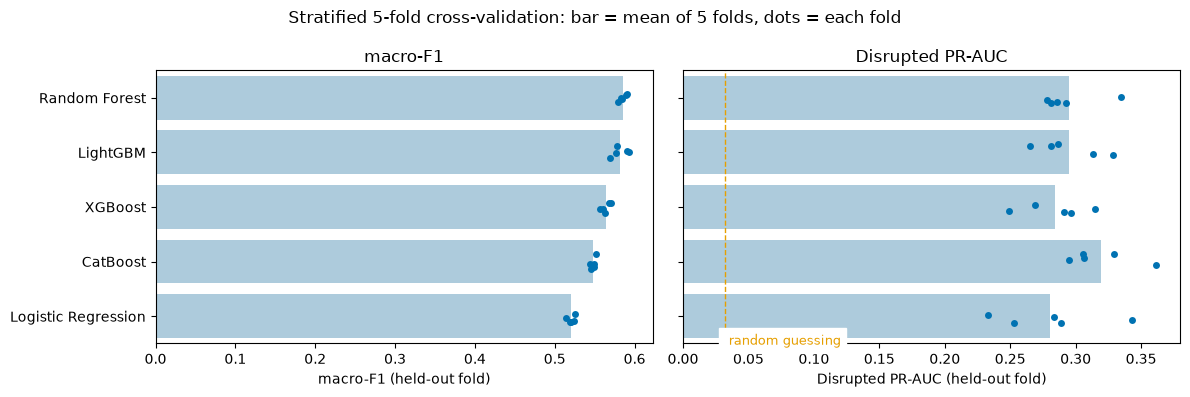

In [8]:
# Mean (bar) and each fold (dots) for the two main scores
okabe_ito_blue, okabe_ito_orange = "#0072B2", "#E69F00"
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (score, label) in zip(axes, [("macro_f1", "macro-F1"), ("disrupted_pr_auc", "Disrupted PR-AUC")]):
    sns.barplot(data=fold_results_df, y="model", x=score, order=model_order, errorbar=None,
                color=okabe_ito_blue, alpha=0.35, ax=ax)
    sns.stripplot(data=fold_results_df, y="model", x=score, order=model_order,
                  color=okabe_ito_blue, size=5, jitter=0.15, ax=ax)
    ax.set_xlabel(f"{label} (held-out fold)")
    ax.set_ylabel("")
    ax.set_title(label)

# Random guessing scores the Disrupted rate on PR-AUC
disrupted_rate = train_df[target_column].eq("Disrupted").mean()
axes[1].axvline(disrupted_rate, color=okabe_ito_orange, ls="--", lw=1)
axes[1].text(disrupted_rate, 4.45, " random guessing", color=okabe_ito_orange, fontsize=9, va="center", backgroundcolor="white")

fig.suptitle("Stratified 5-fold cross-validation: bar = mean of 5 folds, dots = each fold")
plt.tight_layout()
plt.show()

### Reading the Comparison
- **Random Forest and LightGBM are tied for best macro-F1** (about 0.585 and 0.581). The gap between them (0.004) is smaller than their fold-to-fold spread (0.005-0.010), so neither is clearly better yet. XGBoost (0.564) and CatBoost (0.548) come next.
- **Every tree model beats Logistic Regression** (0.520), so the extra complexity is worth it. The straight-line model can't capture the step-like relationship between the features and the status.
- **CatBoost has the best Disrupted PR-AUC** (0.319 vs. 0.28-0.30 for the others), but the differences are about one fold-to-fold standard deviation, so treat them as a hint, not a result.
- **CatBoost and Logistic Regression catch the most real disruptions** (Disrupted recall 0.72 and 0.79) but raise the most false alarms (precision 0.17 and 0.14). This is mostly a threshold effect: with the class weights, their probabilities lean towards Disrupted, and the default "highest probability wins" rule then flags many rows. PR-AUC doesn't depend on the threshold, and there CatBoost does well, so it might move up once its threshold is tuned (section 9 shows the idea).
- **ROC-AUC is about 0.83-0.84 for every model**, so it barely separates them. For a rare class like Disrupted, PR-AUC and Disrupted recall/precision are more informative.
- **All models are untuned**, and all train in about 2 seconds or less per fold. The literature review found that boosting models usually need tuning to reach their best, so this ranking can change after tuning.

## 8. Look Closer at the Best Model
The best model is chosen automatically: the one with the highest mean macro-F1 across the 5 folds.

The **confusion matrix** below uses the out-of-fold predictions, so every training row is included once, predicted by a model that never saw it. Each row of the matrix is a true status, and is divided by its total, so each row adds up to 100%: the diagonal is the share of that status the model got right.

Best model by mean macro-F1: Random Forest


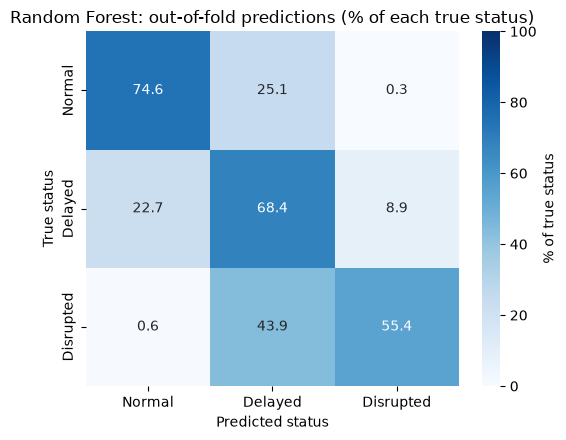

              precision    recall  f1-score   support

      Normal      0.627     0.746     0.681      8211
     Delayed      0.820     0.684     0.746     16030
   Disrupted      0.234     0.554     0.329       799

    accuracy                          0.700     25040
   macro avg      0.560     0.661     0.585     25040
weighted avg      0.738     0.700     0.711     25040



In [9]:
best_model_name = model_order[0]
best_probabilities = out_of_fold_probabilities[best_model_name]
best_predictions = best_probabilities.argmax(axis=1)
print("Best model by mean macro-F1:", best_model_name)

matrix = confusion_matrix(y_train, best_predictions, labels=[0, 1, 2], normalize="true")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matrix * 100, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% of true status"},
            xticklabels=status_order, yticklabels=status_order, ax=ax)
ax.set_xlabel("Predicted status")
ax.set_ylabel("True status")
ax.set_title(f"{best_model_name}: out-of-fold predictions (% of each true status)")
plt.tight_layout()
plt.show()

print(classification_report(y_train, best_predictions, target_names=status_order, digits=3))

### Reading the Mistakes
- The model gets about 75% of Normal rows, 68% of Delayed rows and 55% of Disrupted rows right.
- **Mistakes happen between neighboring statuses.** Missed Disrupted rows are almost always called Delayed (44%), almost never Normal (0.6%). Normal and Delayed are confused with each other about a quarter of the time. That matches how the status is defined: it is the delay cut at 5 and 12 days (02_1), so rows close to a cutoff are the hardest.
- **Disrupted precision is low (0.23):** of the rows the model calls Disrupted, about 1 in 4 really is. Most false alarms are Delayed rows (9% of Delayed rows are flagged as Disrupted), and since Delayed is 20x more common than Disrupted, even a small share of it adds up to many false alarms.

## 9. The Disrupted Decision Threshold
By default a model predicts whichever status has the highest probability. For Disrupted, the business may prefer a different trade-off: catching more real disruptions (higher **recall**) at the cost of more false alarms (lower **precision**), or the other way around.

Here a row is called Disrupted whenever its Disrupted probability is at least a **threshold**. Otherwise, the more likely of Normal and Delayed is predicted. The table shows what happens to Disrupted precision, recall and F1, and to macro-F1, as the threshold changes.

This is a first look using the out-of-fold probabilities. The final threshold should be chosen together with tuning, and then checked once on the test set.

In [10]:
def predict_with_threshold(probabilities, threshold):
    """Disrupted if its probability >= threshold, otherwise the more likely of Normal and Delayed."""
    predictions = probabilities[:, :DISRUPTED].argmax(axis=1)
    predictions[probabilities[:, DISRUPTED] >= threshold] = DISRUPTED
    return predictions

threshold_rows = []
for threshold in np.round(np.arange(0.1, 0.95, 0.05), 2):
    predictions = predict_with_threshold(best_probabilities, threshold)
    threshold_rows.append({
        "threshold": threshold,
        "disrupted_precision": precision_score(y_train == DISRUPTED, predictions == DISRUPTED, zero_division=0),
        "disrupted_recall": recall_score(y_train == DISRUPTED, predictions == DISRUPTED),
        "disrupted_f1": f1_score(y_train == DISRUPTED, predictions == DISRUPTED),
        "macro_f1": f1_score(y_train, predictions, average="macro"),
        "rows flagged Disrupted": int((predictions == DISRUPTED).sum()),
    })

threshold_df = pd.DataFrame(threshold_rows).set_index("threshold")
default_row = pd.Series({
    "disrupted_precision": precision_score(y_train == DISRUPTED, best_predictions == DISRUPTED),
    "disrupted_recall": recall_score(y_train == DISRUPTED, best_predictions == DISRUPTED),
    "disrupted_f1": f1_score(y_train == DISRUPTED, best_predictions == DISRUPTED),
    "macro_f1": f1_score(y_train, best_predictions, average="macro"),
    "rows flagged Disrupted": int((best_predictions == DISRUPTED).sum()),
}, name="default (highest probability)")

pd.concat([default_row.to_frame().T, threshold_df]).round(3)

,disrupted_precision,disrupted_recall,disrupted_f1,macro_f1,rows flagged Disrupted
default (highest probability),0.234,0.554,0.329,0.585,1893.0
0.1,0.093,0.905,0.168,0.447,7795.0
0.15,0.112,0.860,0.199,0.484,6121.0
0.2,0.128,0.810,0.222,0.508,5038.0
0.25,0.147,0.771,0.246,0.528,4203.0
0.3,0.164,0.728,0.267,0.544,3553.0
0.35,0.181,0.683,0.286,0.557,3013.0
0.4,0.201,0.642,0.306,0.570,2555.0
0.45,0.219,0.586,0.318,0.579,2141.0
0.5,0.245,0.542,0.337,0.589,1767.0


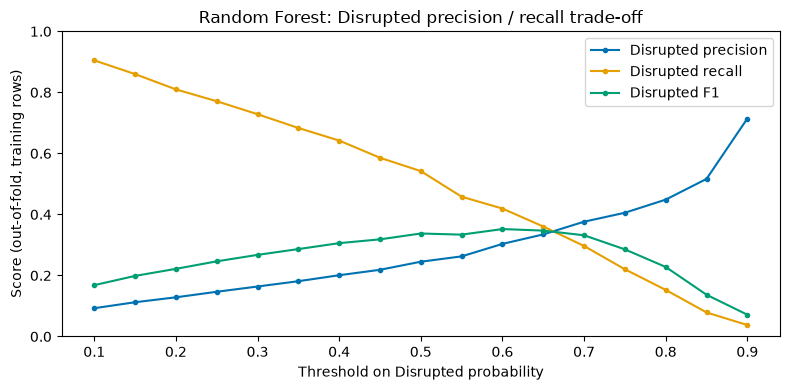

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for column, color, label in [("disrupted_precision", "#0072B2", "Disrupted precision"),
                             ("disrupted_recall", "#E69F00", "Disrupted recall"),
                             ("disrupted_f1", "#009E73", "Disrupted F1")]:
    ax.plot(threshold_df.index, threshold_df[column], marker="o", ms=3, color=color, label=label)
ax.set_xlabel("Threshold on Disrupted probability")
ax.set_ylabel("Score (out-of-fold, training rows)")
ax.set_ylim(0, 1)
ax.set_title(f"{best_model_name}: Disrupted precision / recall trade-off")
ax.legend()
plt.tight_layout()
plt.show()

### Reading the Threshold Trade-off
- The default rule (highest probability wins) behaves like a threshold of about 0.5: it flags 1,893 rows, catching 55% of real disruptions with 23% precision.
- **Raising the threshold to about 0.6-0.65 gives the best Disrupted F1 (about 0.35) and the best macro-F1 (about 0.60)**, but the model then catches only 36-42% of real disruptions.
- **Lowering it to about 0.3 catches 73% of real disruptions**, but only 16% of the flagged rows are real disruptions.

Which threshold is "best" is a **business decision**, not just a score: how costly is a missed disruption compared with a false alarm? If missing a disruption is expensive, a lower threshold is better even though F1 drops.

Note: these numbers are measured on the same out-of-fold predictions they would be chosen from, so they are slightly optimistic. The final threshold should be picked during tuning and then checked once on the test set.

## 10. Which Features Does the Best Model Use?
**Permutation importance:** shuffle one feature's values in the held-out fold, so it no longer matches its rows, and measure how much macro-F1 drops. A big drop means the model relies on that feature. Each fold's model is scored on its own held-out part, and the drops are averaged over the 5 folds (each feature is shuffled 5 times per fold).

This is more reliable than the built-in "importance" numbers of tree models, which can favor features with many distinct values.

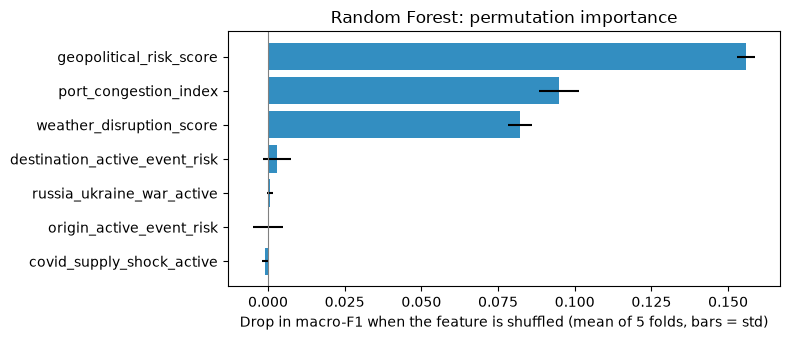

,macro-F1 drop (mean),std across folds
geopolitical_risk_score,0.1557,0.0030
port_congestion_index,0.0949,0.0065
weather_disruption_score,0.0821,0.0040
destination_active_event_risk,0.0031,0.0045
russia_ukraine_war_active,0.0007,0.0010
origin_active_event_risk,-0.0000,0.0049
covid_supply_shock_active,-0.0008,0.0010


In [12]:
importance_by_fold = []
for model, (_, valid_index) in zip(fitted_models[best_model_name], folds):
    result = permutation_importance(model, X_train.iloc[valid_index], y_train.iloc[valid_index],
                                    scoring="f1_macro", n_repeats=5, random_state=42, n_jobs=1)
    importance_by_fold.append(pd.Series(result.importances_mean, index=feature_columns))

importance_df = pd.concat(importance_by_fold, axis=1)
importance_summary = pd.DataFrame({
    "macro-F1 drop (mean)": importance_df.mean(axis=1),
    "std across folds": importance_df.std(axis=1),
}).sort_values("macro-F1 drop (mean)", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(importance_summary.index[::-1], importance_summary["macro-F1 drop (mean)"][::-1],
        xerr=importance_summary["std across folds"][::-1], color="#0072B2", alpha=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled (mean of 5 folds, bars = std)")
ax.set_title(f"{best_model_name}: permutation importance")
plt.tight_layout()
plt.show()

importance_summary.round(4)

### Reading the Importance
- **The model relies on 3 features:** `geopolitical_risk_score` (shuffling it costs about 0.16 macro-F1), `port_congestion_index` (about 0.09) and `weather_disruption_score` (about 0.08). This matches 02_1 and 02_2.
- **The 4 event features are close to 0** (each within its fold-to-fold spread). The Random Forest barely uses them. In 02_2 the event group gave a small improvement with a different model (`HistGradientBoostingClassifier`), so it should be re-tested with the tuned final model. If it still adds nothing, dropping it would make the model simpler and easier to explain.

## 11. Summary
**Setup:** stratified 5-fold cross-validation on the 25,040 training rows, balanced class weights (no resampling), 7 features from 02_2, all models with untuned starting settings. The test set was not used.

**Results (mean ± std over the 5 folds)**

| Model | macro-F1 | Disrupted F1 | Disrupted recall | Disrupted PR-AUC |
|---|---|---|---|---|
| Random Forest | 0.585 ± 0.005 | 0.329 ± 0.017 | 0.554 ± 0.034 | 0.295 ± 0.023 |
| LightGBM | 0.581 ± 0.010 | 0.318 ± 0.034 | 0.471 ± 0.058 | 0.295 ± 0.025 |
| XGBoost | 0.564 ± 0.006 | 0.294 ± 0.019 | 0.557 ± 0.040 | 0.284 ± 0.026 |
| CatBoost | 0.548 ± 0.003 | 0.275 ± 0.009 | 0.722 ± 0.021 | 0.319 ± 0.027 |
| Logistic Regression | 0.520 ± 0.004 | 0.238 ± 0.012 | 0.790 ± 0.031 | 0.280 ± 0.042 |

**What we learned**
1. Tree models clearly beat the linear baseline. Random Forest and LightGBM are tied for best macro-F1; CatBoost ranks Disrupted rows best (highest PR-AUC) but flags too many with the default threshold.
2. Mistakes are between neighboring statuses (Normal <-> Delayed, Delayed <-> Disrupted), never Normal <-> Disrupted.
3. The Disrupted threshold is a real lever: about 0.6 maximizes F1, about 0.3 catches about 3 in 4 disruptions. The right choice depends on the cost of a missed disruption vs. a false alarm.
4. The model relies on geopolitical risk, port congestion and weather. The event features add almost nothing.

**Next steps**
- **Tune** Random Forest, LightGBM and CatBoost (the top 3) with the same stratified folds, e.g. a randomized search over tree depth/leaves, number of trees, learning rate and minimum rows per leaf.
- **Choose the Disrupted threshold** inside the folds, ideally with the team agreeing on the cost of a missed disruption vs. a false alarm.
- **Re-test the event features** with the tuned model, and drop them if they still add nothing.
- **Final evaluation:** score the chosen model **once** on the test set, and also report the score for test rows from 2026-06-07 onward (where Disrupted is much more common).